# RouteOpt — Experiment 003: Comparing OR-Tools with Existing TSP Algorithms

**Goal:** compare Google OR-Tools with Nearest Neighbor, 2-opt, Nearest Neighbor + 2-opt, and Brute Force on the same reproducible synthetic TSP instances.

This notebook uses the same customer counts and 30 random seeds as the robustness experiment. This keeps the instances matched and makes route-quality comparisons fair.

## Research question and experiment design

**Research question:** On the same Euclidean TSP instances, how do route quality and execution time from OR-Tools compare with our existing methods?

**Methods:** Nearest Neighbor; 2-opt applied to a Nearest Neighbor route; the complete Nearest Neighbor + 2-opt pipeline; OR-Tools RoutingModel; and Brute Force on small instances only.

**Matched setup:** customer counts 5, 8, 12, and 20; seeds 2024–2053 (30 per size); depot at (50, 50); customer coordinates sampled uniformly in a 100 × 100 square. Each method is evaluated on each same generated instance. Timings are the median of three runs.

**OR-Tools configuration:** one vehicle, depot node 0, `PATH_CHEAPEST_ARC` initial solution, `GUIDED_LOCAL_SEARCH`, and a 0.05-second search time limit per run. Distances are rounded to integer costs at scale 1,000 for the solver; reported route distances are recomputed from the original floating-point coordinates. Brute Force is run only for at most 8 customers.

The 2-opt-only time is reported for reference. For a fair runtime comparison with a standalone solver, use the complete NN + 2-opt pipeline time.

## Step 1 — Locate the project and import the benchmark

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in (cwd, *cwd.parents) if (path / 'src' / 'benchmark.py').exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not find src/benchmark.py from the current directory')
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
print(f'Project root: {PROJECT_ROOT}')

Project root: /Users/marcoshoejer/Desktop/routeopt


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from benchmark import (
    DEFAULT_CUSTOMER_SIZES,
    ORTOOLS_TIME_LIMIT_SECONDS,
    environment_metadata,
    run_benchmark,
)

CUSTOMER_SIZES = (5, 8, 12, 20)
SEEDS = tuple(range(2024, 2054))
REPETITIONS = 3
print(environment_metadata())
print(f'OR-Tools time limit per run: {ORTOOLS_TIME_LIMIT_SECONDS} seconds')

{'python': '3.11.8 (v3.11.8:db85d51d3e, Feb  6 2024, 18:02:37) [Clang 13.0.0 (clang-1300.0.29.30)]', 'platform': 'macOS-26.6.2-arm64-arm-64bit', 'numpy': '1.26.4', 'pandas': '2.2.3', 'matplotlib': '3.9.3', 'ortools': '9.14.6206'}
OR-Tools time limit per run: 0.05 seconds


## Step 2 — Run the matched benchmark

This cell runs 120 instances. The exact method is deliberately omitted above 8 customers because exhaustive search grows factorially. OR-Tools is given the same time limit for every instance; the search may return before the limit if the solver finishes.

In [3]:
results = run_benchmark(
    customer_sizes=CUSTOMER_SIZES,
    seeds=SEEDS,
    repetitions=REPETITIONS,
)
print(f'Benchmark rows: {len(results)}')
display(results.head())

Benchmark rows: 120


,customers,seed,nearest_neighbor_distance,two_opt_distance,nearest_neighbor_two_opt_distance,ortools_distance,exact_distance,nearest_neighbor_time_s,two_opt_time_s,nearest_neighbor_two_opt_total_time_s,ortools_time_s,brute_force_time_s,nearest_neighbor_gap_pct,two_opt_gap_pct,ortools_gap_pct,nearest_neighbor_route,two_opt_route,nearest_neighbor_two_opt_route,ortools_route
0,5,2024,315.787997,255.508764,255.508764,255.508764,255.508764,0.000114,0.000462,0.000466,0.050857,0.001189,23.591846,0.0,1.112358e-14,"[0, 1, 5, 4, 2, 3, 0]","[0, 3, 1, 5, 4, 2, 0]","[0, 3, 1, 5, 4, 2, 0]","[0, 2, 4, 5, 1, 3, 0]"
1,5,2025,266.354868,240.668715,240.668715,240.668715,240.668715,0.000024,0.000192,0.000211,0.050845,0.001026,10.672826,0.0,0.000000e+00,"[0, 5, 1, 3, 2, 4, 0]","[0, 5, 3, 1, 2, 4, 0]","[0, 5, 3, 1, 2, 4, 0]","[0, 5, 3, 1, 2, 4, 0]"
2,5,2026,201.818799,194.780931,194.780931,194.780931,194.780931,0.000022,0.000281,0.000308,0.050738,0.001029,3.613222,0.0,1.459163e-14,"[0, 2, 5, 4, 3, 1, 0]","[0, 3, 1, 2, 5, 4, 0]","[0, 3, 1, 2, 5, 4, 0]","[0, 4, 5, 2, 1, 3, 0]"
3,5,2027,180.901988,180.901988,180.901988,180.901988,180.901988,0.000030,0.000105,0.000122,0.050950,0.001080,0.000000,0.0,0.000000e+00,"[0, 3, 4, 2, 1, 5, 0]","[0, 3, 4, 2, 1, 5, 0]","[0, 3, 4, 2, 1, 5, 0]","[0, 3, 4, 2, 1, 5, 0]"
4,5,2028,275.566185,226.482751,226.482751,226.482751,226.482751,0.000022,0.000187,0.000209,0.050756,0.001031,21.672041,0.0,0.000000e+00,"[0, 1, 4, 3, 5, 2, 0]","[0, 5, 3, 4, 2, 1, 0]","[0, 5, 3, 4, 2, 1, 0]","[0, 1, 2, 4, 3, 5, 0]"


## Step 3 — Summarize quality and runtime

Mean and standard deviation describe route distance across the 30 instances of each size. Median runtime is reported for each method. `NN + 2-opt` includes both construction and improvement, unlike the 2-opt-only timing.

An exact optimality gap is available only for 5- and 8-customer instances. OR-Tools is a heuristic search under a finite time limit; a zero gap on a small instance means it matched the Brute Force result for that instance, not that it always guarantees optimality.

In [4]:
summary = (
    results.groupby('customers', as_index=False)
    .agg(
        instances=('seed', 'count'),
        nn_distance_mean=('nearest_neighbor_distance', 'mean'),
        nn_distance_std=('nearest_neighbor_distance', 'std'),
        two_opt_distance_mean=('two_opt_distance', 'mean'),
        nn_two_opt_distance_mean=('nearest_neighbor_two_opt_distance', 'mean'),
        ortools_distance_mean=('ortools_distance', 'mean'),
        ortools_distance_std=('ortools_distance', 'std'),
        exact_distance_mean=('exact_distance', 'mean'),
        nn_time_median_s=('nearest_neighbor_time_s', 'median'),
        two_opt_only_time_median_s=('two_opt_time_s', 'median'),
        nn_two_opt_total_time_median_s=('nearest_neighbor_two_opt_total_time_s', 'median'),
        ortools_time_median_s=('ortools_time_s', 'median'),
        brute_force_time_median_s=('brute_force_time_s', 'median'),
        nn_gap_mean_pct=('nearest_neighbor_gap_pct', 'mean'),
        two_opt_gap_mean_pct=('two_opt_gap_pct', 'mean'),
        ortools_gap_mean_pct=('ortools_gap_pct', 'mean'),
    )
)
display(summary.round(4))

,customers,instances,nn_distance_mean,nn_distance_std,two_opt_distance_mean,nn_two_opt_distance_mean,ortools_distance_mean,ortools_distance_std,exact_distance_mean,nn_time_median_s,two_opt_only_time_median_s,nn_two_opt_total_time_median_s,ortools_time_median_s,brute_force_time_median_s,nn_gap_mean_pct,two_opt_gap_mean_pct,ortools_gap_mean_pct
0,5,30,235.6450,40.7499,223.6420,223.6420,223.0464,38.8484,223.0464,0.0000,0.0002,0.0002,0.0508,0.0011,5.8915,0.235,0.0
1,8,30,300.3499,38.9744,275.8471,275.8471,274.3821,31.9526,274.3821,0.0001,0.0009,0.0010,0.0510,0.5210,9.5759,0.489,0.0
2,12,30,361.1304,50.7892,325.6045,325.6045,321.1131,34.4570,NaN,0.0001,0.0035,0.0036,0.0510,NaN,NaN,NaN,NaN
3,20,30,446.6585,50.3407,399.9726,399.9726,390.8727,32.3162,NaN,0.0003,0.0165,0.0168,0.0516,NaN,NaN,NaN,NaN


## Step 4 — Inspect which method produced the shortest route

The table below counts the number of instances where each method had the shortest measured distance. Brute Force is included only for small instances where it was actually run. Ties are allowed within a small numerical tolerance.

In [5]:
quality_columns = {
    'Nearest Neighbor': 'nearest_neighbor_distance',
    '2-opt from NN': 'two_opt_distance',
    'NN + 2-opt': 'nearest_neighbor_two_opt_distance',
    'OR-Tools': 'ortools_distance',
}
winner_rows = []
for customer_count, group in results.groupby('customers'):
    columns = dict(quality_columns)
    if group['exact_distance'].notna().all():
        columns['Brute Force optimum'] = 'exact_distance'
    distances = group[[*columns.values()]].to_numpy()
    best = distances.min(axis=1, keepdims=True)
    for label, column in columns.items():
        wins = (group[column].to_numpy() <= best[:, 0] + 1e-8).sum()
        winner_rows.append({'customers': customer_count, 'method': label, 'best_or_tied_instances': int(wins)})
winners = pd.DataFrame(winner_rows)
display(winners.pivot(index='customers', columns='method', values='best_or_tied_instances').fillna(0).astype(int))

method,2-opt from NN,Brute Force optimum,NN + 2-opt,Nearest Neighbor,OR-Tools
customers,,,,,
5,27,30,27,8,30
8,25,30,25,5,30
12,17,0,17,3,30
20,9,0,9,0,29


## Step 5 — Plot route quality and computational cost

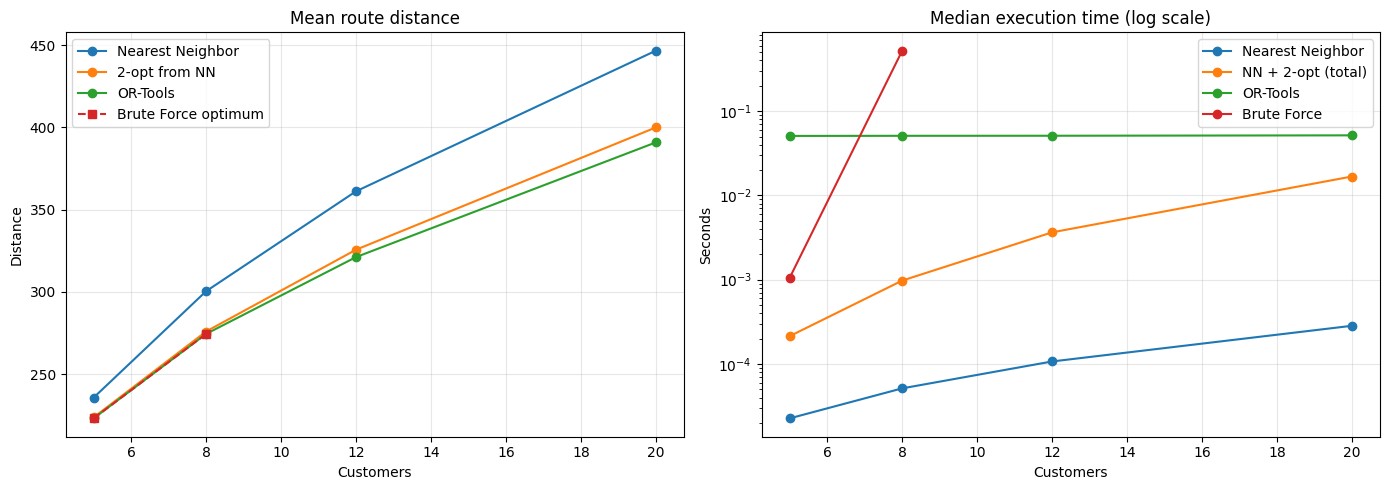

Figure saved to: /Users/marcoshoejer/Desktop/routeopt/results/ortools_comparison.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(summary['customers'], summary['nn_distance_mean'], marker='o', label='Nearest Neighbor')
axes[0].plot(summary['customers'], summary['two_opt_distance_mean'], marker='o', label='2-opt from NN')
axes[0].plot(summary['customers'], summary['ortools_distance_mean'], marker='o', label='OR-Tools')
exact = summary[summary['exact_distance_mean'].notna()]
axes[0].plot(exact['customers'], exact['exact_distance_mean'], marker='s', linestyle='--', label='Brute Force optimum')
axes[0].set(title='Mean route distance', xlabel='Customers', ylabel='Distance')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(summary['customers'], summary['nn_time_median_s'], marker='o', label='Nearest Neighbor')
axes[1].plot(summary['customers'], summary['nn_two_opt_total_time_median_s'], marker='o', label='NN + 2-opt (total)')
axes[1].plot(summary['customers'], summary['ortools_time_median_s'], marker='o', label='OR-Tools')
small = summary[summary['brute_force_time_median_s'].notna()]
axes[1].plot(small['customers'], small['brute_force_time_median_s'], marker='o', label='Brute Force')
axes[1].set_yscale('log')
axes[1].set(title='Median execution time (log scale)', xlabel='Customers', ylabel='Seconds')
axes[1].grid(alpha=0.3)
axes[1].legend()

fig.tight_layout()
figure_path = PROJECT_ROOT / 'results' / 'ortools_comparison.png'
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=160, bbox_inches='tight')
plt.show()
print(f'Figure saved to: {figure_path}')

## Step 6 — Save the raw results

The CSV stores all instance-level routes, distances, runtimes, and exact gaps where available. Keeping these raw observations makes it possible to independently check the summary.

In [7]:
csv_path = PROJECT_ROOT / 'results' / 'ortools_comparison.csv'
results.to_csv(csv_path, index=False)
print(f'Results saved to: {csv_path}')

Results saved to: /Users/marcoshoejer/Desktop/routeopt/results/ortools_comparison.csv


## Results observed in this run

| Customers | NN mean distance | 2-opt mean distance | OR-Tools mean distance | NN + 2-opt median time | OR-Tools median time | Brute Force median time |
|---:|---:|---:|---:|---:|---:|---:|
| 5 | 235.645 | 223.642 | 223.046 | 0.0002 s | 0.0508 s | 0.0011 s |
| 8 | 300.350 | 275.847 | 274.382 | 0.0010 s | 0.0510 s | 0.5210 s |
| 12 | 361.130 | 325.605 | 321.113 | 0.0036 s | 0.0510 s | Not run |
| 20 | 446.659 | 399.973 | 390.873 | 0.0168 s | 0.0516 s | Not run |

OR-Tools produced a shorter mean route than NN + 2-opt at all four sizes, but it required longer median runtime under the configured search limit. It matched the Brute Force optimum on all 30 instances with 5 customers and all 30 instances with 8 customers. For 12 and 20 customers, no exact optimum was computed, so these route lengths are comparisons between methods, not optimality gaps. The per-instance winner table above shows that 2-opt still beat OR-Tools on some instances, especially at smaller sizes.

## Interpretation and limitations

Compare the distance table and winner counts first, then compare runtime using the complete `NN + 2-opt` pipeline rather than the isolated local-search time. Check exact gaps only for the small instances. OR-Tools' 0.05-second search limit is part of the experimental setup: changing it can change both runtime and route quality. The values in this section are observations from this particular run; they are not guarantees for other data or machines.

This remains a synthetic Euclidean TSP experiment. It does not include road-network distances, multiple vehicles, capacity, or delivery time windows. Solver results are affected by the search limit and integer rounding of arc costs; reported distances are recalculated using the original coordinates. Runtime is machine-dependent. Findings should therefore be described as observations on these instances, not as universal rankings.

## Conclusion and next step

In these experiments, OR-Tools achieved the best average route distance, including the exact optimum for every tested 5- and 8-customer instance, but it used more runtime than the NN + 2-opt pipeline. Brute Force remains the exact reference for small instances. The next research step can examine how the tradeoff changes with a different solver time limit, then extend the model to multiple vehicles and operational constraints.